# 机器视觉入门

这一本 Notebook 包含环境准备、七项图像处理实践和最后的一次作业。按顺序往下读、往下运行即可。

**如何使用：** 首次从第 1 节安装环境并选择内核；环境准备好后，用单元格左侧的运行按钮逐步执行。想检查完整流程时，选择“重启内核并全部运行”。所有示例图片已在 `assets/` 中提供，结果会自动保存到 `outputs/`。

## 学习顺序

1. 环境准备：Python、VS Code、Jupyter、OpenCV
2. 图像读写与翻转
3. 颜色通道与调整
4. 图像融合
5. 图像直方图
6. 腐蚀与膨胀
7. 图像滤波
8. 边缘提取
9. 一次作业：三张图片、三句说明、一个 PR

各节末尾的问题用于帮助理解，不需要逐题交作业。最终只提交第 9 节的四个文件。


## 1. 环境准备

这一节一次完成 Python 环境、VS Code 扩展和 Notebook 内核的配置，后面不再重复配置。

### 1.1 安装并打开项目

准备 Python **3.11 或 3.12**、VS Code，以及 VS Code 中的 **Python**、**Jupyter** 扩展。克隆培训仓库后，在 VS Code 中打开 `02 机器视觉/lab` 文件夹，再打开本 Notebook。

### 1.2 创建环境并安装依赖

在 VS Code 的终端中执行下面与你的系统对应的命令。终端的当前位置应为 `lab`，能看到 `requirements.txt`。这些是**终端命令**，无需粘贴到 Python 单元格中。首次安装需要联网。

**macOS / Linux：**

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
```

**Windows PowerShell：**

```powershell
py -3.12 -m venv .venv
.\.venv\Scripts\python.exe -m pip install -r requirements.txt
```

上面的 Windows 命令使用 Python 3.12；如果安装的是 3.11，把 `-3.12` 改为 `-3.11`。

### 1.3 选择 Notebook 内核

在右上角点击“选择内核”，选择刚创建的 `.venv` Python 环境。安装依赖时使用的 Python 和 Notebook 内核应属于同一个环境。

现在从下面的 Python 单元格开始运行。如果提示 `No module named cv2`，先检查内核，再确认依赖已安装到该环境。安装包名为 `opencv-python-headless`，代码中的导入名为 `cv2`。

使用独立 JupyterLab 时，在 lab 目录运行 `python -m jupyterlab`；Windows 可运行 `.\.venv\Scripts\python.exe -m jupyterlab`。两种方式使用同一本 Notebook。


In [1]:
from pathlib import Path
import sys
import platform
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 自动寻找本实验的素材，兼容从 lab 或仓库根目录启动。
START = Path.cwd().resolve()
ROOT = None
for candidate in (START, *START.parents):
    if (candidate / "assets" / "bottle_cap.png").is_file():
        ROOT = candidate
        break
    nested = candidate / "02 机器视觉" / "lab"
    if (nested / "assets" / "bottle_cap.png").is_file():
        ROOT = nested
        break
if ROOT is None:
    raise FileNotFoundError("请打开完整的 02 机器视觉/lab 文件夹后再运行。")

ASSETS = ROOT / "assets"
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)
print("Python:", platform.python_version())
print("OpenCV:", cv2.__version__)
print("当前内核:", sys.executable)
print("素材准备完成，共 5 张基础图片。")


Matplotlib is building the font cache; this may take a moment.


Python: 3.12.14
OpenCV: 4.14.0
当前内核: /private/tmp/opencv_lab_verify/bin/python
素材准备完成，共 5 张基础图片。


### 1.4 准备读图、显示和保存工具

下面几个函数负责读图、显示和保存，后面会反复使用。先运行这一格；暂时不必逐行记忆。

- `read_image("文件名")`：读取素材，返回 OpenCV 图像数组。
- `show_images({...})`：在单元格下方显示对比图。
- `save_image("文件名", 图像)`：把处理结果保存到 `outputs/`。

OpenCV 用 **BGR** 顺序保存彩色通道，Matplotlib 用 **RGB** 顺序显示彩色图；显示函数会完成这一步转换。图片直接显示在 Notebook 中，不需要另开图像窗口。


In [2]:
import math

def read_image(name, gray=False):
    path = ASSETS / name
    if not path.is_file():
        raise FileNotFoundError(f"找不到素材：{path}")
    flags = cv2.IMREAD_GRAYSCALE if gray else cv2.IMREAD_COLOR
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), flags)
    if image is None:
        raise ValueError(f"图片解码失败：{path}")
    return image

def save_image(name, image):
    if image.dtype != np.uint8:
        raise TypeError("保存前请将图像转换为 uint8。")
    path = OUT / name
    path.parent.mkdir(parents=True, exist_ok=True)
    ok, encoded = cv2.imencode(path.suffix, image)
    if not ok:
        raise OSError(f"无法保存图片：{path}")
    encoded.tofile(str(path))

def show_images(images, cols=2, save_to=None):
    fig, axes = plt.subplots(math.ceil(len(images) / cols), cols,
                             figsize=(cols * 4, math.ceil(len(images) / cols) * 4),
                             squeeze=False)
    for ax, (title, image) in zip(axes.flat, images.items()):
        if image.ndim == 2:
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        else:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(title)
        ax.axis("off")
    for ax in list(axes.flat)[len(images):]:
        ax.axis("off")
    fig.tight_layout()
    if save_to:
        path = OUT / save_to
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()
    plt.close(fig)


### 1.5 验证环境

运行后应看到瓶盖照片，以及图像的高度、宽度和通道数。图中的标题使用英文，说明使用中文，减少电脑字体差异带来的显示问题。

Notebook 中的变量会保留。如果重启内核，需要先重新运行第 1 节，再运行后续章节。每个图像处理章节都会重新读取自己的输入，不依赖上一章的结果。


图像形状（高、宽、通道）: (370, 370, 3)
数据类型: uint8


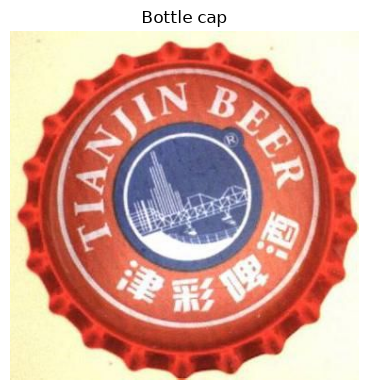

In [3]:
sample_cap = read_image("bottle_cap.png")
print("图像形状（高、宽、通道）:", sample_cap.shape)
print("数据类型:", sample_cap.dtype)
show_images({"Bottle cap": sample_cap}, cols=1)


## 2. 图像读写与翻转

**这一节要会：** 读取图片，观察图像数组，完成翻转并保存。

一张彩色图像可以看作“高度 × 宽度 × 3”的数组。`cv2.flip` 的参数为 `1` 时左右翻转，为 `0` 时上下翻转，为 `-1` 时同时翻转两个方向。

### 2.1 读取硬币照片


shape: (419, 632, 3) dtype: uint8


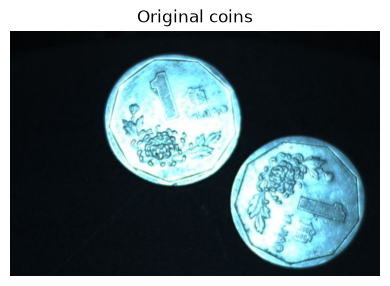

In [4]:
coins = read_image("coins.png")
print("shape:", coins.shape, "dtype:", coins.dtype)
show_images({"Original coins": coins}, cols=1)


### 2.2 翻转、保存、重新读取

运行后比较三幅图中硬币的位置。PNG 是无损格式，保存后重新读取应与处理结果逐像素相同。


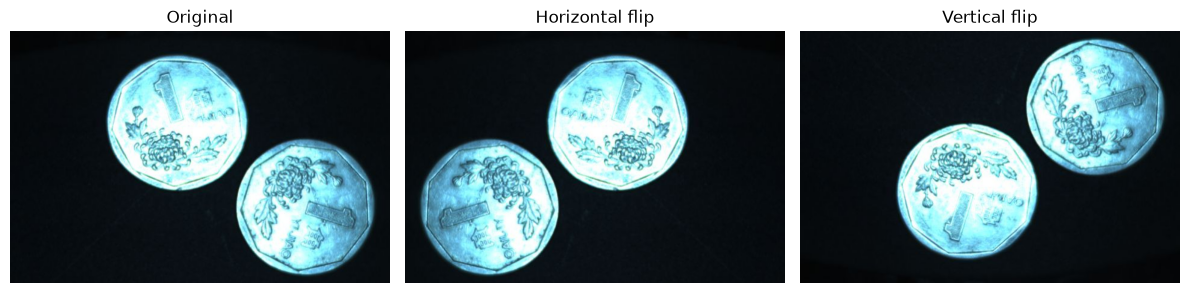

In [5]:
coins_horizontal = cv2.flip(coins, 1)
coins_vertical = cv2.flip(coins, 0)
save_image("coins_horizontal.png", coins_horizontal)

# 重新读取刚保存的 PNG，验证读写结果。
coins_reloaded = cv2.imdecode(np.fromfile(str(OUT / "coins_horizontal.png"), dtype=np.uint8), cv2.IMREAD_COLOR)
assert np.array_equal(coins_reloaded, coins_horizontal)
show_images({"Original": coins, "Horizontal flip": coins_horizontal,
             "Vertical flip": coins_vertical}, cols=3,
            save_to="flip_comparison.png")


**停下来观察：** 水平翻转改变的是左右位置，还是上下位置？可把输入改成 `panda.jpg` 再试一次。这是学习练习，无需单独提交。


## 3. 颜色通道与调整

**这一节要会：** 区分 B、G、R 三个通道，修改通道数值，观察颜色变化。

每个通道通常使用 0–255 的整数。把某通道数值调高，会增强它对最终颜色的贡献。计算时先转为浮点数，再裁剪到 0–255，避免 uint8 直接相加发生回绕。

### 3.1 分离三个通道

单通道以灰度显示，越亮表示该通道的数值越大。


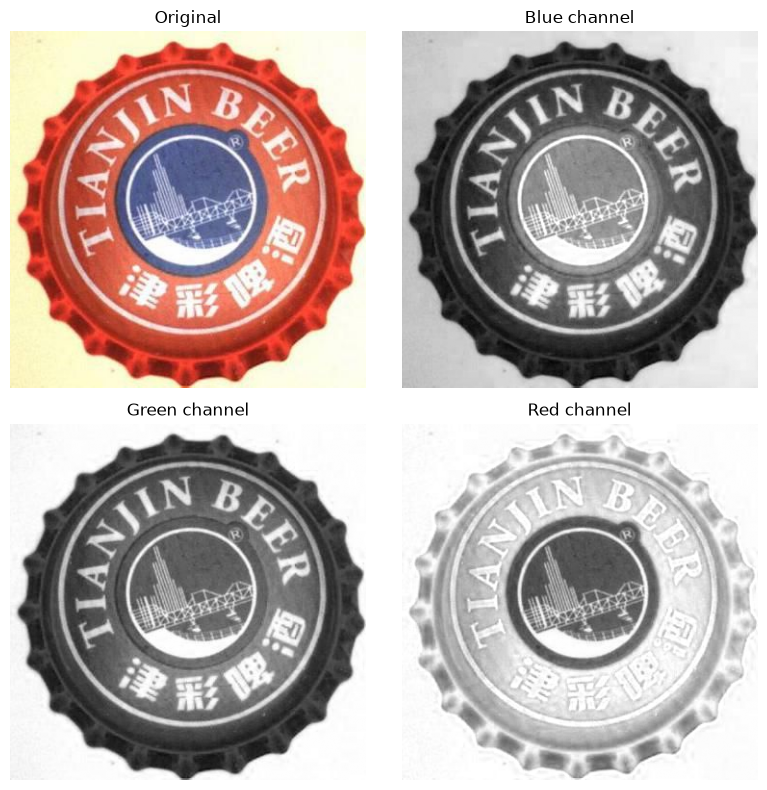

In [6]:
color_cap = read_image("bottle_cap.png")
blue_channel, green_channel, red_channel = cv2.split(color_cap)
show_images({"Original": color_cap, "Blue channel": blue_channel,
             "Green channel": green_channel, "Red channel": red_channel}, cols=2,
            save_to="color_channels.png")


### 3.2 修改通道

下面的 `(0, 0, 40)` 表示蓝色不变、绿色不变、红色增加 40。可以将最后的 40 改成 80，再运行这一格，比较瓶盖颜色的变化。


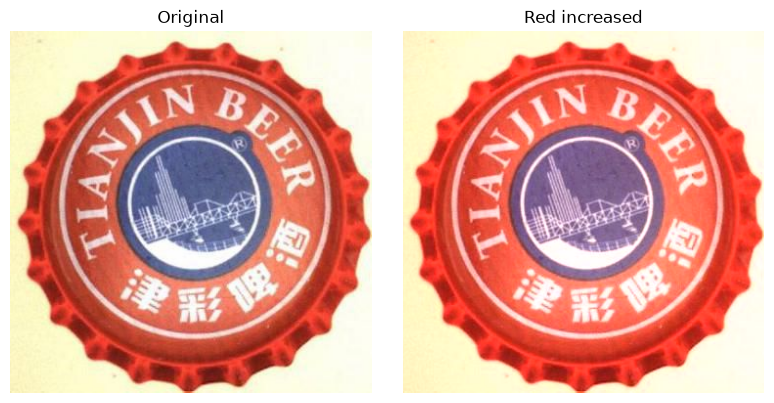

In [7]:
offset_bgr = np.array([0, 0, 40], dtype=np.float32)
color_adjusted = np.clip(color_cap.astype(np.float32) + offset_bgr, 0, 255).astype(np.uint8)
show_images({"Original": color_cap, "Red increased": color_adjusted}, cols=2,
            save_to="color_comparison.png")
save_image("cap_color_adjusted.png", color_adjusted)


### 3.3 颜色量化

量化将接近的像素值归到同一个等级，例如每 64 个数值归为一组。等级越少，色块越明显。下面的中间计算使用 uint16，最后再转回 uint8。


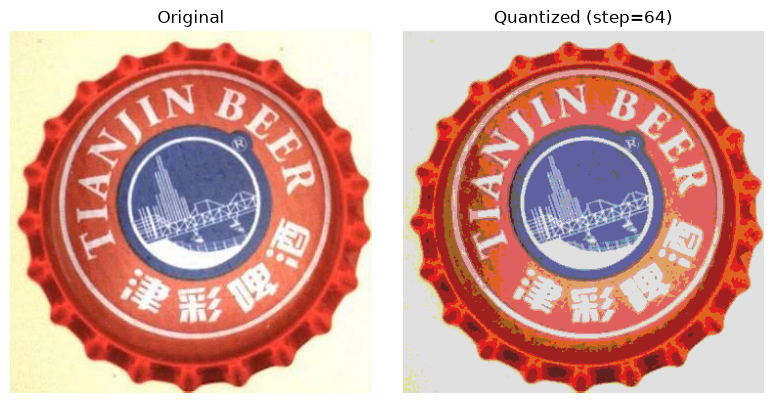

In [8]:
quantization_step = 64
color_work = color_cap.astype(np.uint16)
color_quantized = np.clip((color_work // quantization_step) * quantization_step
                          + quantization_step // 2, 0, 255).astype(np.uint8)
show_images({"Original": color_cap, "Quantized (step=64)": color_quantized}, cols=2,
            save_to="quantization.png")


**停下来观察：** 增加红色通道与减少颜色等级，产生的变化一样吗？也可以把偏移量改为 `(40, 0, 0)`，观察蓝色通道增加后的效果。


## 4. 图像融合

**这一节要会：** 选定一块局部区域（ROI），把两幅图按权重相加。

融合公式为 `结果 = (1-alpha) × 底图 + alpha × 叠加图`。两幅参与计算的图像必须尺寸相同、通道数相同。这里使用熊猫照片作底图，把瓶盖缩放到局部区域大小后叠加。瓶盖的浅色背景也会参与融合。

### 4.1 准备底图与叠加图


In [9]:
blend_background = read_image("panda.jpg")
blend_cap = read_image("bottle_cap.png")
blend_h, blend_w = 180, 180
blend_x, blend_y = 20, blend_background.shape[0] - blend_h - 20
assert 0 <= blend_x and 0 <= blend_y
assert blend_x + blend_w <= blend_background.shape[1] and blend_y + blend_h <= blend_background.shape[0]
blend_patch = cv2.resize(blend_cap, (blend_w, blend_h), interpolation=cv2.INTER_AREA)
blend_roi = blend_background[blend_y:blend_y+blend_h, blend_x:blend_x+blend_w]


### 4.2 比较融合权重

alpha 越大，瓶盖越明显。`cv2.add` 直接叠加两个输入，超出 255 的部分会截为 255，可能出现过亮的区域。


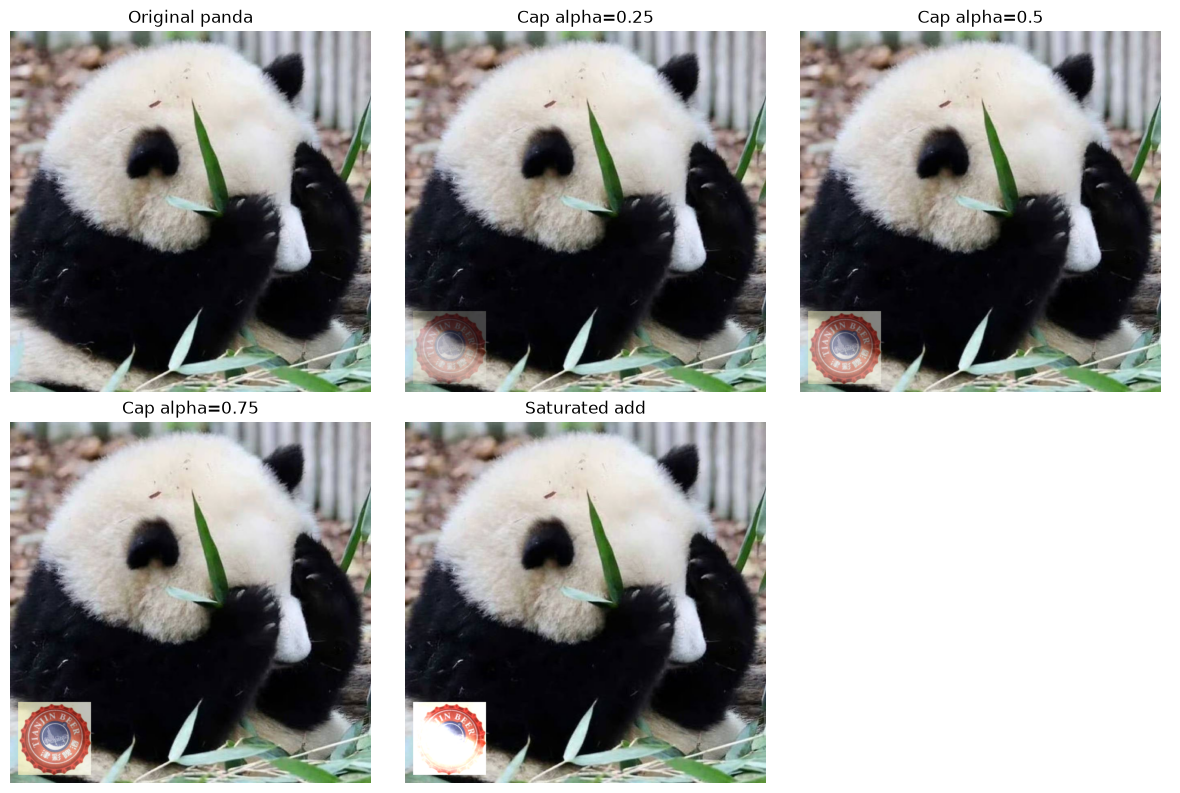

In [10]:
blend_views = {"Original panda": blend_background}
for blend_alpha in (0.25, 0.5, 0.75):
    blend_result = blend_background.copy()
    blend_result[blend_y:blend_y+blend_h, blend_x:blend_x+blend_w] = cv2.addWeighted(
        blend_roi, 1-blend_alpha, blend_patch, blend_alpha, 0)
    blend_views[f"Cap alpha={blend_alpha}"] = blend_result

blend_added = blend_background.copy()
blend_added[blend_y:blend_y+blend_h, blend_x:blend_x+blend_w] = cv2.add(blend_roi, blend_patch)
blend_views["Saturated add"] = blend_added
show_images(blend_views, cols=3, save_to="blend_comparison.png")


### 4.3 只对一个通道融合

下例只修改蓝色通道，其他两个通道保持不变。通道编号 0、1、2 依次表示蓝、绿、红。


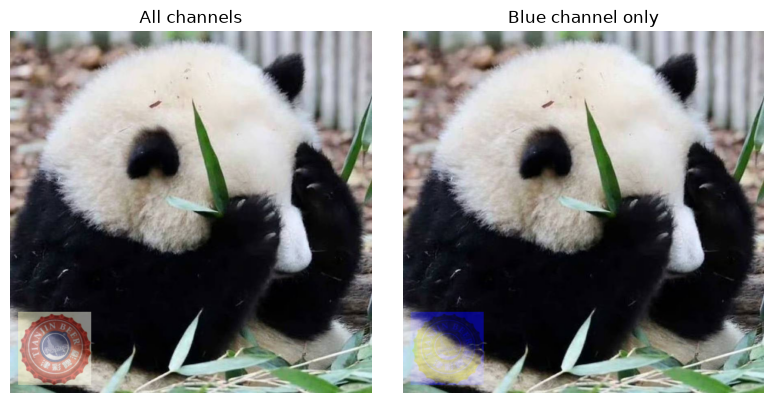

In [11]:
blend_channels = list(cv2.split(blend_background))
blend_gray_patch = cv2.cvtColor(blend_patch, cv2.COLOR_BGR2GRAY)
blend_channel_id = 0
blend_channel_roi = blend_channels[blend_channel_id][blend_y:blend_y+blend_h, blend_x:blend_x+blend_w]
blend_channels[blend_channel_id][blend_y:blend_y+blend_h, blend_x:blend_x+blend_w] = cv2.addWeighted(
    blend_channel_roi, 0.5, blend_gray_patch, 0.5, 0)
blend_single_channel = cv2.merge(blend_channels)
show_images({"All channels": blend_views["Cap alpha=0.5"],
             "Blue channel only": blend_single_channel}, cols=2,
            save_to="blend_single_channel.png")


**停下来观察：** alpha 为 0、1 时，各自会得到什么？直接相加与加权融合，哪一种更容易出现过亮区域？


## 5. 图像直方图

**这一节要会：** 看懂横轴的灰度值和纵轴的像素数量。

灰度直方图统计 0–255 各个灰度级有多少像素。它描述明暗分布，不记录像素在图中什么位置。OpenCV 的范围写成 `[0, 256]`，右端 256 不包含在统计区间中。

### 5.1 瓶盖灰度直方图

观察瓶盖的浅色背景，并找出它在直方图中大致对应的区间。


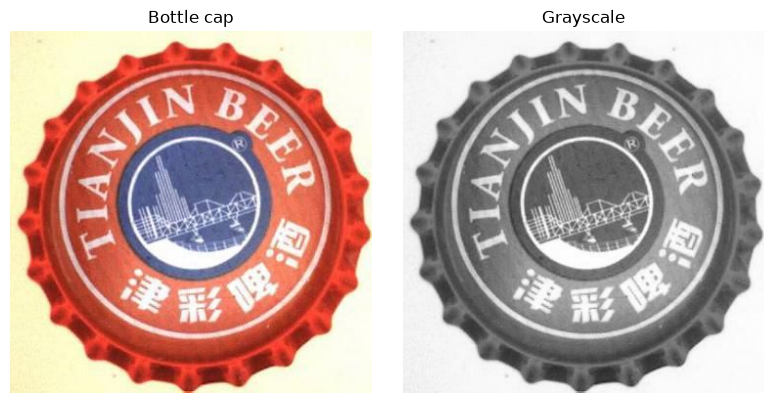

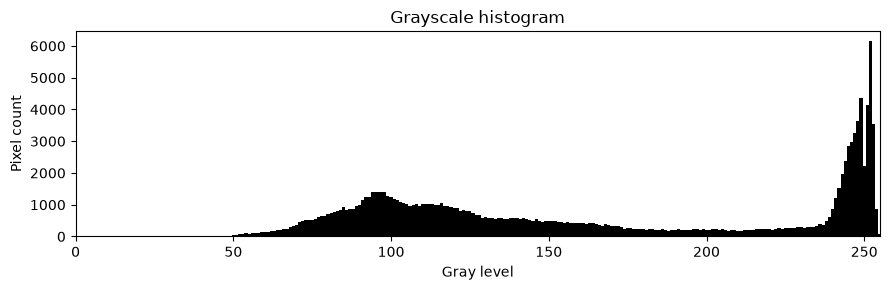

In [12]:
hist_cap = read_image("bottle_cap.png")
hist_gray = cv2.cvtColor(hist_cap, cv2.COLOR_BGR2GRAY)
hist_counts = cv2.calcHist([hist_gray], [0], None, [256], [0, 256]).ravel()
assert int(hist_counts.sum()) == hist_gray.size
show_images({"Bottle cap": hist_cap, "Grayscale": hist_gray}, cols=2)

hist_fig, hist_ax = plt.subplots(figsize=(9, 3))
hist_ax.bar(np.arange(256), hist_counts, width=1, color="black")
hist_ax.set(xlim=(0, 255), xlabel="Gray level", ylabel="Pixel count", title="Grayscale histogram")
hist_fig.tight_layout(); hist_fig.savefig(OUT / "gray_histogram.png", dpi=120)
plt.show(); plt.close(hist_fig)


### 5.2 分别统计三个颜色通道

三条曲线分别表示蓝、绿、红通道的数值分布。


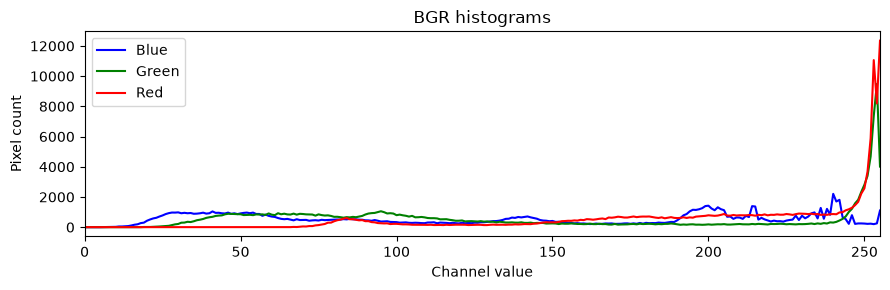

In [13]:
hist_color_fig, hist_color_ax = plt.subplots(figsize=(9, 3))
for hist_channel, hist_color, hist_label in [(0, "b", "Blue"), (1, "g", "Green"), (2, "r", "Red")]:
    hist_values = cv2.calcHist([hist_cap], [hist_channel], None, [256], [0, 256]).ravel()
    hist_color_ax.plot(hist_values, color=hist_color, label=hist_label)
hist_color_ax.set(xlim=(0, 255), xlabel="Channel value", ylabel="Pixel count", title="BGR histograms")
hist_color_ax.legend(); hist_color_fig.tight_layout()
hist_color_fig.savefig(OUT / "color_histograms.png", dpi=120)
plt.show(); plt.close(hist_color_fig)


**停下来观察：** 瓶盖背景较亮，直方图哪一端的像素较多？把图像水平翻转，直方图会改变吗？下面验证第二个问题。


In [14]:
hist_flipped = cv2.calcHist([cv2.flip(hist_gray, 1)], [0], None, [256], [0, 256]).ravel()
assert np.array_equal(hist_counts, hist_flipped)
print("翻转前后像素位置改变，但灰度直方图相同。")


翻转前后像素位置改变，但灰度直方图相同。


## 6. 腐蚀与膨胀

**这一节要会：** 区分灰度图与白色前景二值图中的变化。

灰度腐蚀在局部区域取最小值，膨胀取最大值。当二值图以白色为前景时，腐蚀使白色区域缩小，膨胀使白色区域扩大。结构元素（核）定义了处理时观察的邻域。

### 6.1 对电路板灰度图处理

电路板芯片较暗。灰度腐蚀会使暗色区域扩大，因此不能把“腐蚀”直接理解为任何物体都变小。


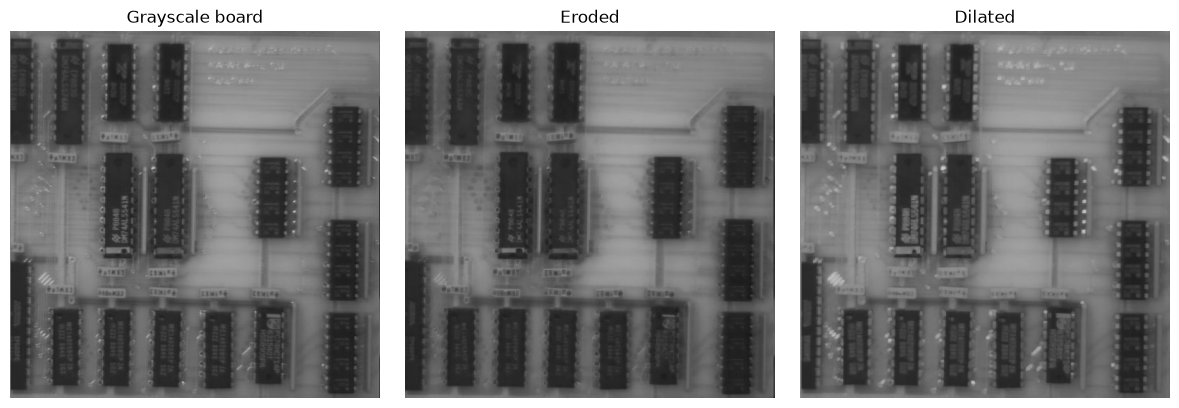

In [15]:
morph_board = read_image("circuit_board.png", gray=True)
morph_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))
morph_eroded = cv2.erode(morph_board, morph_kernel, iterations=1)
morph_dilated = cv2.dilate(morph_board, morph_kernel, iterations=1)
show_images({"Grayscale board": morph_board, "Eroded": morph_eroded,
             "Dilated": morph_dilated}, cols=3, save_to="board_morphology.png")


### 6.2 把零件设为白色前景

原照片中的零件较暗。使用反二值化，并让 Otsu 方法自动选择阈值，得到“白色零件、黑色背景”的二值图，再比较处理后的边界和孔洞。


白色面积 [腐蚀后, 原始, 膨胀后]: [88813, 100715, 111569]


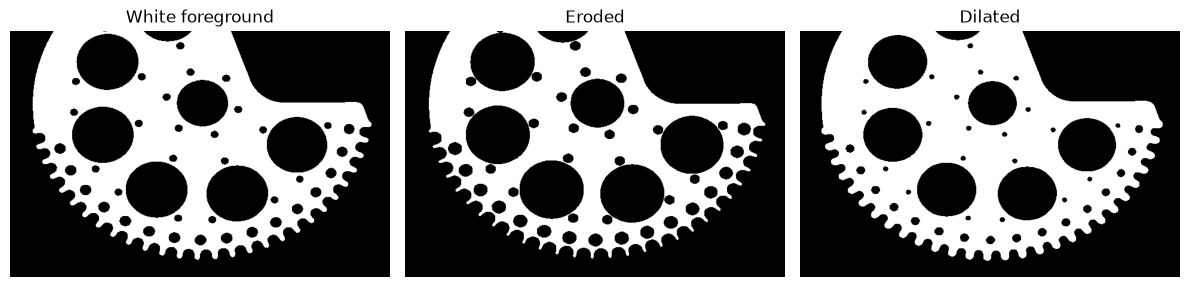

In [16]:
morph_part = read_image("mechanical_part.png", gray=True)
morph_threshold, morph_binary = cv2.threshold(morph_part, 0, 255, cv2.THRESH_BINARY_INV | cv2.THRESH_OTSU)
morph_part_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
morph_part_eroded = cv2.erode(morph_binary, morph_part_kernel)
morph_part_dilated = cv2.dilate(morph_binary, morph_part_kernel)
morph_areas = [int(np.count_nonzero(a)) for a in (morph_part_eroded, morph_binary, morph_part_dilated)]
assert morph_areas[0] <= morph_areas[1] <= morph_areas[2]
print("白色面积 [腐蚀后, 原始, 膨胀后]:", morph_areas)
show_images({"White foreground": morph_binary, "Eroded": morph_part_eroded,
             "Dilated": morph_part_dilated}, cols=3, save_to="binary_morphology.png")


### 6.3 延伸观察：开运算与闭运算

开运算先腐蚀再膨胀，闭运算先膨胀再腐蚀。尝试观察它们对细小突出和细小孔洞的影响。这部分不需要交作业。


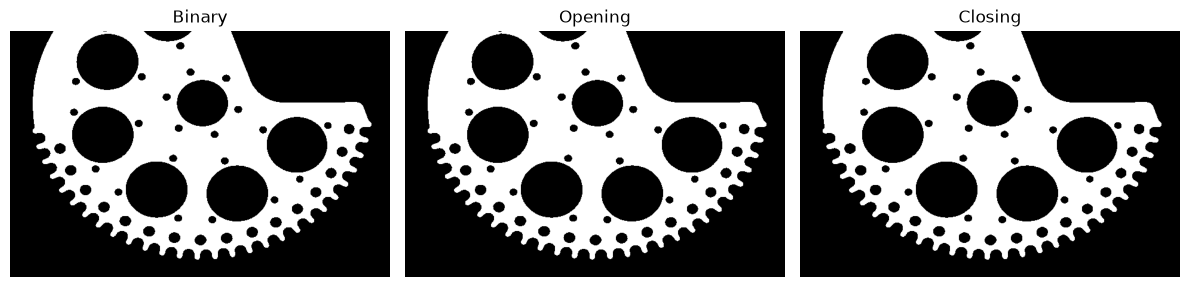

In [17]:
morph_opened = cv2.morphologyEx(morph_binary, cv2.MORPH_OPEN, morph_part_kernel)
morph_closed = cv2.morphologyEx(morph_binary, cv2.MORPH_CLOSE, morph_part_kernel)
show_images({"Binary": morph_binary, "Opening": morph_opened,
             "Closing": morph_closed}, cols=3, save_to="opening_closing.png")


**停下来观察：** 白色零件腐蚀后，外轮廓和内部黑色孔洞分别怎样变化？把核从 5×5 改成 9×9，细节会怎样？


## 7. 图像滤波

**这一节要会：** 选择一种滤波方法，观察噪点是否减少、细节是否变模糊。

滤波使用像素附近的值来计算新的像素值。均值滤波使用邻域平均值；高斯滤波对距离中心更近的像素赋予更大权重；中值滤波取邻域中间的数值，常用于椒盐噪声。

### 7.1 准备带噪声的瓶盖图

用原图生成高斯噪声图和椒盐噪声图。随机种子固定为 2026，便于重复观察。原始素材不被覆盖。


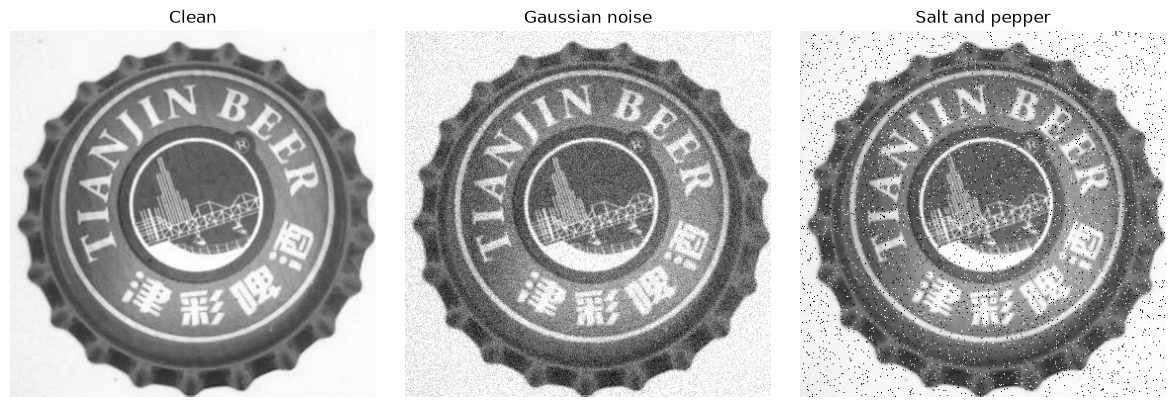

In [18]:
filter_clean = read_image("bottle_cap.png", gray=True)
filter_rng = np.random.default_rng(2026)
filter_gaussian_input = np.clip(filter_clean.astype(np.float32)
    + filter_rng.normal(0, 20, filter_clean.shape), 0, 255).astype(np.uint8)
filter_salt_input = filter_clean.copy()
filter_random = filter_rng.random(filter_clean.shape)
filter_salt_input[filter_random < 0.025] = 0
filter_salt_input[filter_random > 0.975] = 255
show_images({"Clean": filter_clean, "Gaussian noise": filter_gaussian_input,
             "Salt and pepper": filter_salt_input}, cols=3, save_to="noise_inputs.png")
save_image("cap_gaussian_noise.png", filter_gaussian_input)
save_image("cap_salt_pepper.png", filter_salt_input)


### 7.2 比较三种滤波

先在椒盐噪声图上比较。核大小都取 5，观察黑白噪点、文字和瓶盖边缘。不需要计算误差。


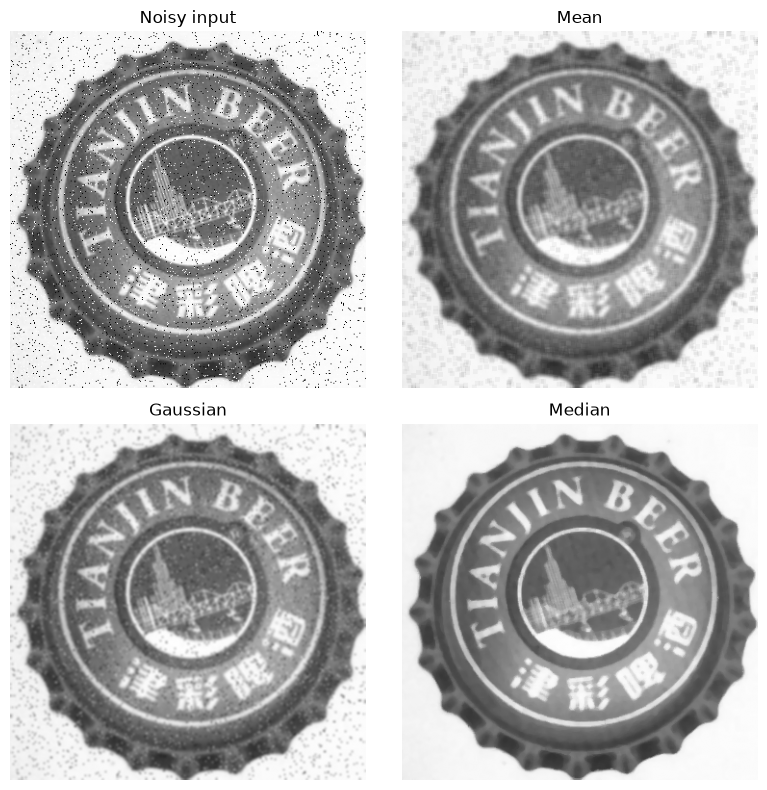

In [19]:
filter_mean = cv2.blur(filter_salt_input, (5, 5))
filter_gaussian = cv2.GaussianBlur(filter_salt_input, (5, 5), 1.2)
filter_median = cv2.medianBlur(filter_salt_input, 5)
show_images({"Noisy input": filter_salt_input, "Mean": filter_mean,
             "Gaussian": filter_gaussian, "Median": filter_median}, cols=2,
            save_to="filter_comparison.png")


### 7.3 延伸观察：平滑与锐化

在电路板上比较高斯、中值滤波。然后用“原图减去平滑图”得到高频细节，再把一部分细节加回原图，观察锐化。浮点运算可以保留差值中的负数。这部分不需要交作业。


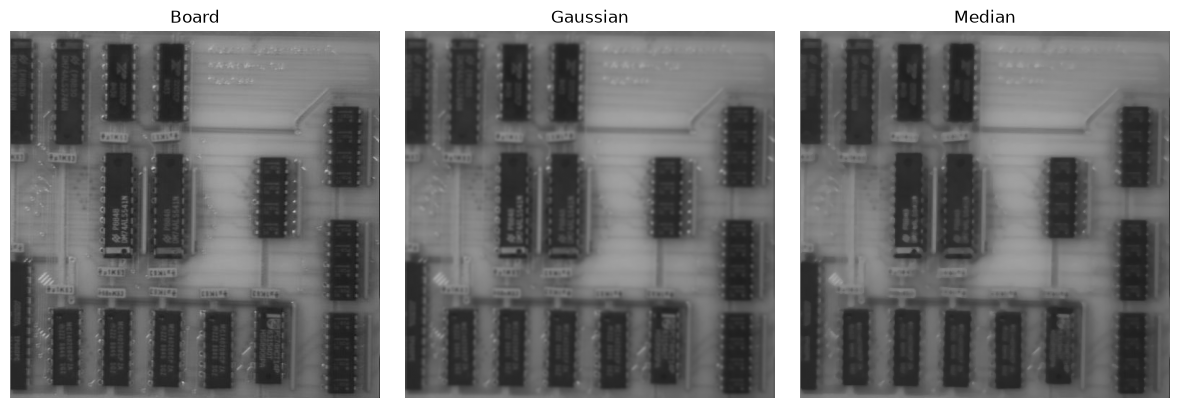

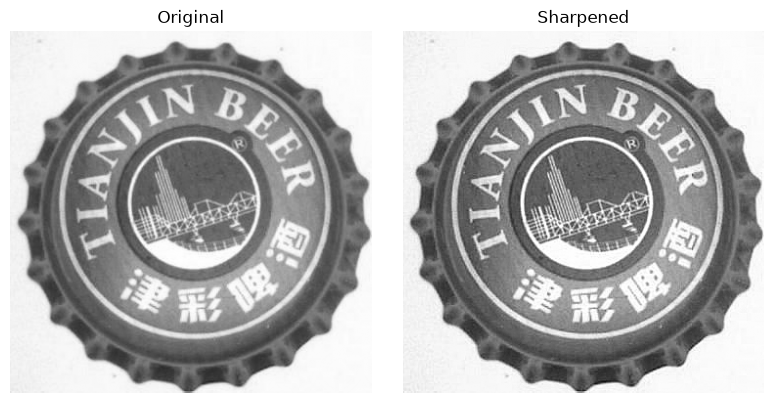

In [20]:
filter_board = read_image("circuit_board.png", gray=True)
show_images({"Board": filter_board, "Gaussian": cv2.GaussianBlur(filter_board, (5, 5), 1.5),
             "Median": cv2.medianBlur(filter_board, 5)}, cols=3, save_to="board_filters.png")
filter_lowpass = cv2.GaussianBlur(filter_clean, (5, 5), 1.2).astype(np.float32)
filter_detail = filter_clean.astype(np.float32) - filter_lowpass
filter_sharpened = np.clip(filter_clean.astype(np.float32) + filter_detail, 0, 255).astype(np.uint8)
show_images({"Original": filter_clean, "Sharpened": filter_sharpened}, cols=2,
            save_to="sharpening.png")


**停下来观察：** 你认为哪幅图中的噪点最少？文字是否也变模糊了？可以把同一组滤波代码中的输入换成 `filter_gaussian_input`，观察另一种噪声。


## 8. 边缘提取

**这一节要会：** 观察两个方向的亮度变化，合成边缘，再调整阈值。

Sobel x 计算沿 x 方向的亮度变化，通常对竖直边缘响应强；Sobel y 通常对水平边缘响应强。梯度有正负值，先使用 float32 计算，取绝对值并合成后再转换为显示图，避免直接用 uint8 丢失负梯度。

### 8.1 计算方向梯度与合成结果


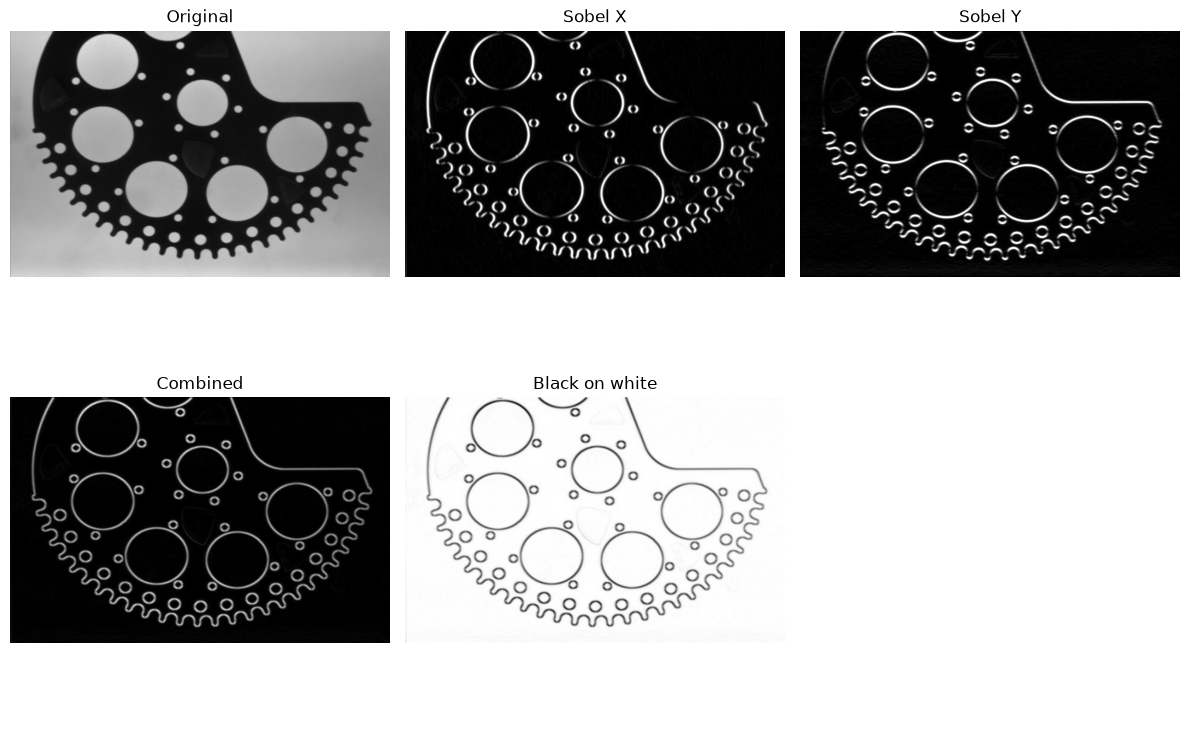

In [21]:
edge_part = read_image("mechanical_part.png", gray=True)
edge_smoothed = cv2.GaussianBlur(edge_part, (3, 3), 0)
edge_x = cv2.Sobel(edge_smoothed, cv2.CV_32F, 1, 0, ksize=3)
edge_y = cv2.Sobel(edge_smoothed, cv2.CV_32F, 0, 1, ksize=3)

def normalize_edges(values):
    maximum = float(values.max())
    if maximum == 0:
        return np.zeros(values.shape, dtype=np.uint8)
    return np.clip(values * (255.0 / maximum), 0, 255).astype(np.uint8)

edge_strength = normalize_edges(np.abs(edge_x) + np.abs(edge_y))
assert normalize_edges(np.zeros((8, 8), dtype=np.float32)).max() == 0
show_images({"Original": edge_part, "Sobel X": cv2.convertScaleAbs(edge_x),
             "Sobel Y": cv2.convertScaleAbs(edge_y), "Combined": edge_strength,
             "Black on white": 255-edge_strength}, cols=3, save_to="sobel_comparison.png")


### 8.2 观察阈值的影响

在归一化的边缘强度上设阈值，超过阈值的像素保留为白色。阈值越高，保留的边缘像素通常越少。


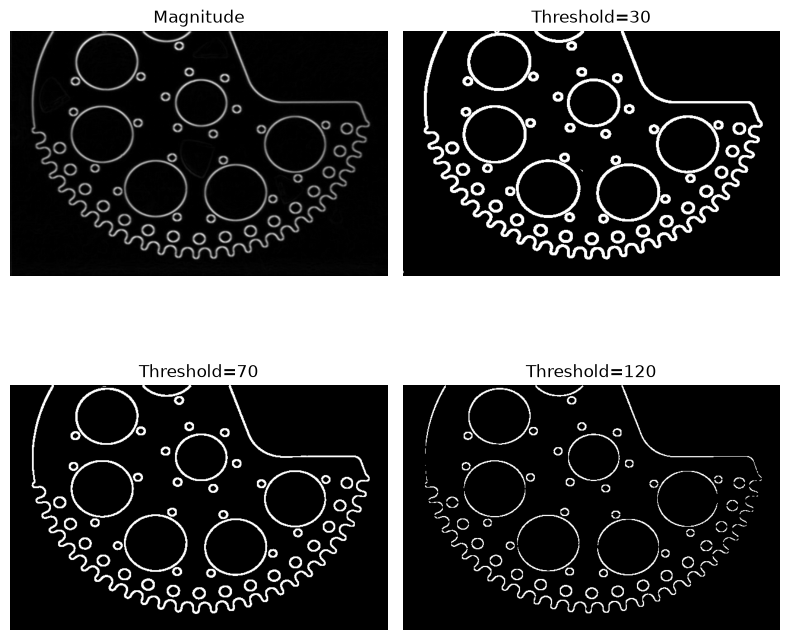

In [22]:
edge_views = {"Magnitude": edge_strength}
edge_counts = []
for edge_threshold in (30, 70, 120):
    _, edge_binary = cv2.threshold(edge_strength, edge_threshold, 255, cv2.THRESH_BINARY)
    edge_views[f"Threshold={edge_threshold}"] = edge_binary
    edge_counts.append(int(np.count_nonzero(edge_binary)))
assert edge_counts[0] >= edge_counts[1] >= edge_counts[2]
show_images(edge_views, cols=2, save_to="edge_thresholds.png")


### 8.3 换成自然照片

熊猫毛发和竹叶有很多纹理。与机械零件相比，边缘提取可能得到更多内部细节。


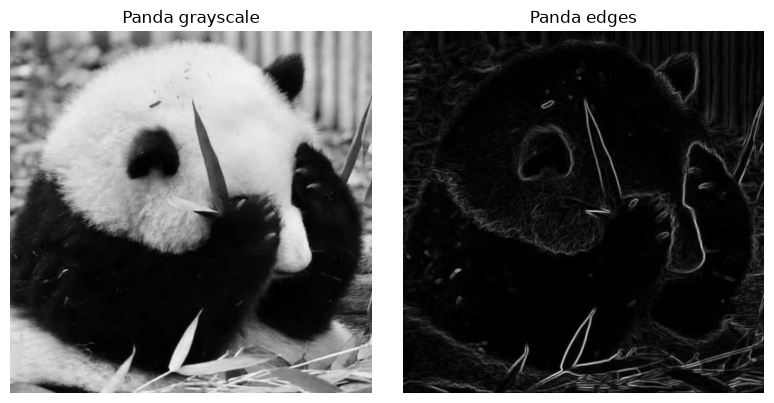

In [23]:
edge_panda = read_image("panda.jpg", gray=True)
edge_panda_blur = cv2.GaussianBlur(edge_panda, (5, 5), 1.2)
edge_panda_x = cv2.Sobel(edge_panda_blur, cv2.CV_32F, 1, 0, ksize=3)
edge_panda_y = cv2.Sobel(edge_panda_blur, cv2.CV_32F, 0, 1, ksize=3)
edge_panda_result = normalize_edges(cv2.magnitude(edge_panda_x, edge_panda_y))
show_images({"Panda grayscale": edge_panda, "Panda edges": edge_panda_result}, cols=2,
            save_to="panda_edges.png")


**停下来观察：** 边缘图是否只保留物体的外轮廓？提高阈值后，哪些线条先消失？


## 9. 一次作业：三张图片、三句说明、一个 PR

作业只交一次。下面三个单元格会直接生成需要提交的三张对比图。只需运行第 1 节准备环境，再运行这三个单元格，也能生成作业图片；它们不依赖前面练习中保存的变量。

**任务一：水平翻转。** 运行下一格，观察原图与水平翻转结果中硬币位置的变化。


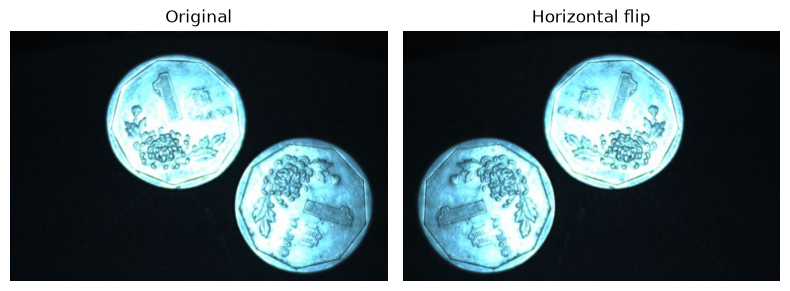

已保存：outputs/作业图片/01_flip.png


In [24]:
hw_coins = read_image("coins.png")
hw_coins_flipped = cv2.flip(hw_coins, 1)
show_images({"Original": hw_coins, "Horizontal flip": hw_coins_flipped}, cols=2,
            save_to="作业图片/01_flip.png")
print("已保存：outputs/作业图片/01_flip.png")


**任务二：颜色调整。** 课堂示例给红色通道增加 40。这里将它改成 80，再运行；也可以选择其他偏移量。观察调整前后的变化，并记下自己修改的通道和数值。


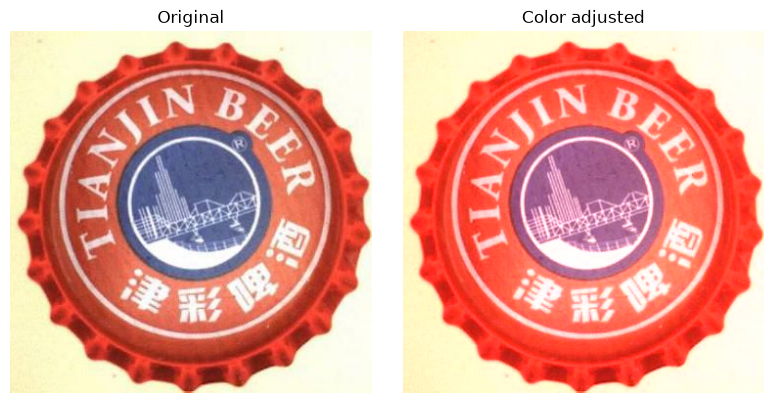

已保存：outputs/作业图片/02_color.png


In [25]:
hw_cap = read_image("bottle_cap.png")
hw_offset_bgr = np.array([0, 0, 80], dtype=np.float32)  # 蓝、绿、红
hw_color_result = np.clip(hw_cap.astype(np.float32) + hw_offset_bgr, 0, 255).astype(np.uint8)
show_images({"Original": hw_cap, "Color adjusted": hw_color_result}, cols=2,
            save_to="作业图片/02_color.png")
print("已保存：outputs/作业图片/02_color.png")


**任务三：选择一种滤波。** 默认用中值滤波处理带椒盐噪声的瓶盖图。可以保持默认，也可以将滤波一行替换为注释中的任意一种。只观察噪点和细节，不需要计算误差、比较多个方法或解释公式。


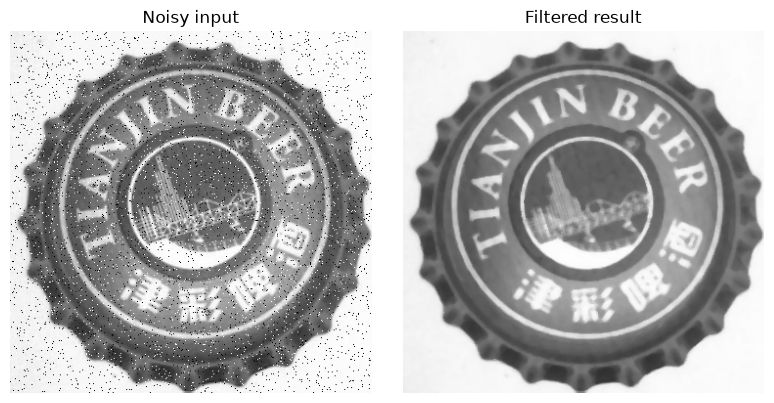

已保存：outputs/作业图片/03_filter.png


In [26]:
hw_clean = read_image("bottle_cap.png", gray=True)
hw_rng = np.random.default_rng(2026)
hw_random = hw_rng.random(hw_clean.shape)
hw_noisy = hw_clean.copy()
hw_noisy[hw_random < 0.025] = 0
hw_noisy[hw_random > 0.975] = 255

hw_filtered = cv2.medianBlur(hw_noisy, 5)
# hw_filtered = cv2.blur(hw_noisy, (5, 5))
# hw_filtered = cv2.GaussianBlur(hw_noisy, (5, 5), 1.2)

show_images({"Noisy input": hw_noisy, "Filtered result": hw_filtered}, cols=2,
            save_to="作业图片/03_filter.png")
print("已保存：outputs/作业图片/03_filter.png")


### 9.1 整理提交文件

将 `outputs/作业图片/` 中的三张图片复制到 `submissions/你的GitHub用户名/`，再新建一个 `README.md`。最终只需要这四个文件：

```text
submissions/
└── 你的GitHub用户名/
    ├── 01_flip.png
    ├── 02_color.png
    ├── 03_filter.png
    └── README.md
```

把下面的文字复制到自己的 `README.md`，填写三句说明：

```markdown
# 实验作业

1. 翻转：使用了____图片，水平翻转后____。
2. 颜色调整：将____通道的偏移量设为____，图像变得____。
3. 滤波：使用了____滤波，处理后____。
```

### 9.2 提交一个 PR

1. 将培训仓库 Fork 到自己的 GitHub 账号，克隆自己的 Fork，并创建作业分支，例如 `assignment/你的GitHub用户名`。如果前面已使用自己的 Fork，继续使用即可。
2. 在 VS Code 的源代码管理中，只暂存自己提交目录里的四个文件，提交并推送到自己的 Fork。运行后本 Notebook 与 `outputs/` 也可能显示已修改，这些练习文件不用加入作业 PR。
3. 从作业分支向教师仓库 `WHUT-RMers/27Tutorials` 的默认分支发起 PR，标题填写 `[作业] 你的GitHub用户名`，按 PR 模板勾选完成项。
4. 提交前检查文件列表：应只有 `02 机器视觉/lab/submissions/你的GitHub用户名/` 中的三张图片和一份说明。需要修改时，继续向同一分支提交，原 PR 会更新，无需新建 PR。

### 9.3 完成标准

采用“通过 / 补充后通过”：三张对比图完整、处理效果可辨认、三句说明与图片一致，即可通过。某种滤波效果不明显时，可以如实写出观察到的现象。不要求提交 Notebook、代码、长篇报告或前面各节的思考题。
